# 07 – Customer Lifetime Value (CLV) Analysis

## Objective
The objective of this analysis is to estimate the value of Netflix customers using their subscription and payment history. It aims to identify high-value, medium-value, and low-value customers and understand how customer value differs across customer segments.

## Business Questions
1. Who are the highest-value customers?
2. How does estimated customer value vary across subscription plans?
3. Which customer segments contribute the most estimated revenue?
4. How do customer engagement and payment behaviour relate to customer value?

## Methodology
- Load the feature-engineered customer dataset and customer segmentation dataset.
- Combine customer information with cluster assignments.
- Calculate estimated customer value using available subscription and payment data.
- Group customers into value categories.
- Compare customer value across customer segments and subscription plans.
- Visualize the findings and prepare business recommendations.

## Important Note
The available dataset contains historical payment and subscription information. Therefore, the CLV calculated in this notebook will be an estimate based on available data, not a guaranteed prediction of future customer revenue.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the feature-engineered dataset
features_df = pd.read_csv('/content/netflix_feature_engineered.csv')

# Load the customer segmentation dataset
segments_df = pd.read_csv('/content/netflix_customer_segments.csv')

# Display dataset shapes
print("Feature-engineered dataset:", features_df.shape)
print("Customer segmentation dataset:", segments_df.shape)

# Display first five rows
display(features_df.head())
display(segments_df.head())

Feature-engineered dataset: (8000, 36)
Customer segmentation dataset: (8000, 37)


,customer_id,age,gender,country,acquisition_channel,customer_segment,preferred_language,plan_id,subscription_start_date,monthly_price,auto_renew,subscription_tenure_days,payment_count,failed_payment_count,average_payment_amount,total_payment_amount,payment_failure_rate,viewing_sessions,total_watch_minutes,average_watch_minutes,average_completion_percentage,average_session_duration,unique_content_watched,unique_devices_used,support_ticket_count,average_resolution_hours,average_support_satisfaction,unique_issue_categories,feedback_count,average_feedback_rating,negative_feedback_count,positive_feedback_count,churned,has_viewing_activity,has_support_tickets,has_feedback
0,CUST000744,21.00,Female,United Kingdom,Organic Search,Individual,English,PLAN03,2019-06-03,22.99,False,2584,15,2,22.99,344.85,0.13,5.00,266.00,53.20,70.20,60.80,5.00,4.00,0.00,13.40,3.00,0.00,1.00,3.00,0.00,0.00,0,1,0,1
1,CUST001502,31.00,Male,Canada,Referral,Family,French,PLAN01,2026-01-13,6.99,True,168,5,0,6.99,34.95,0.00,5.00,309.00,61.80,72.80,72.60,5.00,2.00,0.00,13.40,3.00,0.00,0.00,3.00,0.00,0.00,0,1,0,0
2,CUST005383,40.00,Male,United Kingdom,Paid Social,Student,English,PLAN01,2023-06-17,6.99,True,1109,15,1,6.52,97.86,0.07,6.00,301.00,50.17,76.50,58.67,6.00,4.00,0.00,13.40,3.00,0.00,1.00,4.00,0.00,1.00,0,1,0,1
3,CUST004708,27.00,Male,United Kingdom,Partner Bundle (Telecom),Individual,Hindi,PLAN02,2019-03-09,15.49,False,2497,15,1,15.49,232.35,0.07,10.00,389.00,38.90,63.90,45.10,10.00,3.00,0.00,13.40,3.00,0.00,0.00,3.00,0.00,0.00,1,1,0,0
4,CUST005877,36.00,Male,Indonesia,Email Campaign,Student,French,PLAN03,2025-12-03,22.99,True,209,6,1,19.16,114.95,0.17,5.00,286.00,57.20,60.80,65.20,5.00,2.00,0.00,13.40,3.00,0.00,0.00,3.00,0.00,0.00,0,1,0,0


,customer_id,age,gender,country,acquisition_channel,customer_segment,preferred_language,plan_id,subscription_start_date,monthly_price,auto_renew,subscription_tenure_days,payment_count,failed_payment_count,average_payment_amount,total_payment_amount,payment_failure_rate,viewing_sessions,total_watch_minutes,average_watch_minutes,average_completion_percentage,average_session_duration,unique_content_watched,unique_devices_used,support_ticket_count,average_resolution_hours,average_support_satisfaction,unique_issue_categories,feedback_count,average_feedback_rating,negative_feedback_count,positive_feedback_count,churned,has_viewing_activity,has_support_tickets,has_feedback,cluster
0,CUST000744,21.00,Female,United Kingdom,Organic Search,Individual,English,PLAN03,2019-06-03,22.99,False,2584,15,2,22.99,344.85,0.13,5.00,266.00,53.20,70.20,60.80,5.00,4.00,0.00,13.40,3.00,0.00,1.00,3.00,0.00,0.00,0,1,0,1,4
1,CUST001502,31.00,Male,Canada,Referral,Family,French,PLAN01,2026-01-13,6.99,True,168,5,0,6.99,34.95,0.00,5.00,309.00,61.80,72.80,72.60,5.00,2.00,0.00,13.40,3.00,0.00,0.00,3.00,0.00,0.00,0,1,0,0,1
2,CUST005383,40.00,Male,United Kingdom,Paid Social,Student,English,PLAN01,2023-06-17,6.99,True,1109,15,1,6.52,97.86,0.07,6.00,301.00,50.17,76.50,58.67,6.00,4.00,0.00,13.40,3.00,0.00,1.00,4.00,0.00,1.00,0,1,0,1,3
3,CUST004708,27.00,Male,United Kingdom,Partner Bundle (Telecom),Individual,Hindi,PLAN02,2019-03-09,15.49,False,2497,15,1,15.49,232.35,0.07,10.00,389.00,38.90,63.90,45.10,10.00,3.00,0.00,13.40,3.00,0.00,0.00,3.00,0.00,0.00,1,1,0,0,4
4,CUST005877,36.00,Male,Indonesia,Email Campaign,Student,French,PLAN03,2025-12-03,22.99,True,209,6,1,19.16,114.95,0.17,5.00,286.00,57.20,60.80,65.20,5.00,2.00,0.00,13.40,3.00,0.00,0.00,3.00,0.00,0.00,0,1,0,0,1


In [3]:
# Keep only customer_id and cluster from the segmentation dataset
cluster_info = segments_df[['customer_id', 'cluster']]

# Merge cluster information with the feature-engineered dataset
clv_df = features_df.merge(
    cluster_info,
    on='customer_id',
    how='left',
    validate='one_to_one'
)

# Check the merged dataset
print("Merged dataset shape:", clv_df.shape)
print("Missing cluster values:", clv_df['cluster'].isnull().sum())
print("Duplicate customer IDs:", clv_df['customer_id'].duplicated().sum())

display(clv_df[['customer_id', 'monthly_price',
                'total_payment_amount', 'subscription_tenure_days',
                'cluster', 'churned']].head())

Merged dataset shape: (8000, 37)
Missing cluster values: 0
Duplicate customer IDs: 0


,customer_id,monthly_price,total_payment_amount,subscription_tenure_days,cluster,churned
0,CUST000744,22.99,344.85,2584,4,0
1,CUST001502,6.99,34.95,168,1,0
2,CUST005383,6.99,97.86,1109,3,0
3,CUST004708,15.49,232.35,2497,4,1
4,CUST005877,22.99,114.95,209,1,0


In [4]:
# Convert subscription tenure from days into months
clv_df['tenure_months'] = (
    clv_df['subscription_tenure_days'] / 30.44
)

# Calculate estimated subscription value
clv_df['estimated_subscription_value'] = (
    clv_df['monthly_price'] * clv_df['tenure_months']
)

# Historical revenue from recorded payments
clv_df['historical_payment_revenue'] = (
    clv_df['total_payment_amount']
)

# Display customer-level CLV information
display(
    clv_df[[
        'customer_id',
        'monthly_price',
        'subscription_tenure_days',
        'tenure_months',
        'historical_payment_revenue',
        'estimated_subscription_value'
    ]].head(10)
)

# Summary statistics
print("\nEstimated Subscription Value Summary:")
display(clv_df['estimated_subscription_value'].describe())

print("\nHistorical Payment Revenue Summary:")
display(clv_df['historical_payment_revenue'].describe())

,customer_id,monthly_price,subscription_tenure_days,tenure_months,historical_payment_revenue,estimated_subscription_value
0,CUST000744,22.99,2584,84.89,344.85,1951.58
1,CUST001502,6.99,168,5.52,34.95,38.58
2,CUST005383,6.99,1109,36.43,97.86,254.66
3,CUST004708,15.49,2497,82.03,232.35,1270.65
4,CUST005877,22.99,209,6.87,114.95,157.85
5,CUST003762,15.49,261,8.57,123.92,132.82
6,CUST007892,15.49,303,9.95,192.08,154.19
7,CUST002317,6.99,2261,74.28,104.85,519.20
8,CUST005609,15.49,1274,41.85,216.86,648.30
9,CUST000519,22.99,434,14.26,344.85,327.78



Estimated Subscription Value Summary:


,estimated_subscription_value
count,8000.00
mean,559.34
std,461.11
min,0.00
25%,203.18
50%,439.92
75%,805.03
max,2066.38



Historical Payment Revenue Summary:


,historical_payment_revenue
count,8000.00
mean,188.43
std,103.58
min,6.99
25%,104.85
50%,206.91
75%,232.35
max,629.93


In [5]:
# Calculate value thresholds
low_threshold = clv_df['estimated_subscription_value'].quantile(0.25)
high_threshold = clv_df['estimated_subscription_value'].quantile(0.75)

print("Low Value Threshold:", round(low_threshold, 2))
print("High Value Threshold:", round(high_threshold, 2))

# Create customer value categories
clv_df['customer_value_category'] = np.where(
    clv_df['estimated_subscription_value'] < low_threshold,
    'Low Value',
    np.where(
        clv_df['estimated_subscription_value'] < high_threshold,
        'Medium Value',
        'High Value'
    )
)

# Count customers in each category
category_counts = clv_df['customer_value_category'].value_counts()

print("\nCustomer Value Category Distribution:")
display(category_counts.to_frame(name='customer_count'))

# Calculate percentage distribution
category_percentage = (
    clv_df['customer_value_category']
    .value_counts(normalize=True) * 100
)

display(category_percentage.round(2).to_frame(name='percentage'))

Low Value Threshold: 203.18
High Value Threshold: 805.03

Customer Value Category Distribution:


,customer_count
customer_value_category,
Medium Value,3998
High Value,2002
Low Value,2000


,percentage
customer_value_category,
Medium Value,49.98
High Value,25.02
Low Value,25.00


### Step 6 – Customer Value Categorization

**Objective:**  
Group customers into Low, Medium, and High Value categories based on their estimated subscription value.

**Methodology:**  
Used the 25th and 75th percentiles of estimated subscription value as thresholds.

**Key Findings:**
- 2,000 customers (25.00%) belong to the Low Value category.
- 3,998 customers (49.98%) belong to the Medium Value category.
- 2,002 customers (25.02%) belong to the High Value category.
- The low-value threshold is 203.18.
- The high-value threshold is 805.03.

**Interpretation:**  
Approximately half of the customers fall into the Medium Value category, while one-quarter are in each of the Low and High Value categories. This segmentation can help the business plan customer retention and engagement strategies.

**Conclusion:**  
Customer value categorization provides a simple way to identify different customer groups and prioritize business strategies.

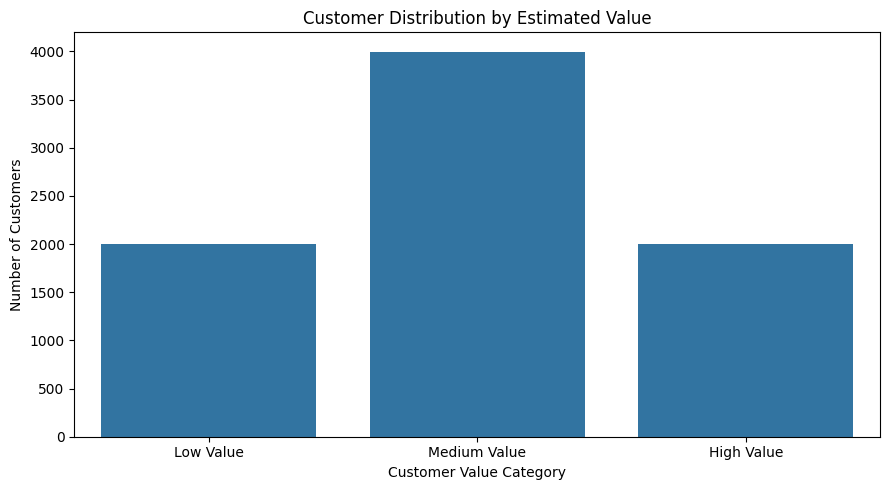

In [6]:
# Count customers in each value category
category_order = ['Low Value', 'Medium Value', 'High Value']

plt.figure(figsize=(9, 5))

sns.countplot(
    data=clv_df,
    x='customer_value_category',
    order=category_order
)

plt.title('Customer Distribution by Estimated Value')
plt.xlabel('Customer Value Category')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

### Step 7 – Customer Value Distribution Visualization

**Objective:**  
Visualize the distribution of customers across the three estimated value categories.

**Visualization:**  
A bar chart was created to compare the number of Low, Medium, and High Value customers.

**Key Findings:**
- Medium Value customers form the largest group, with 3,998 customers.
- Low Value customers account for 2,000 customers.
- High Value customers account for 2,002 customers.

**Business Interpretation:**  
The visualization shows that nearly half of the customer base belongs to the Medium Value category. The business can focus on retaining high-value customers and improving engagement among medium-value customers.

In [7]:
# Compare estimated customer value across subscription plans

plan_clv = clv_df.groupby('plan_id').agg(
    customer_count=('customer_id', 'count'),
    average_monthly_price=('monthly_price', 'mean'),
    average_estimated_value=('estimated_subscription_value', 'mean'),
    average_historical_revenue=('historical_payment_revenue', 'mean')
).reset_index()

plan_clv = plan_clv.round(2)

display(plan_clv)

,plan_id,customer_count,average_monthly_price,average_estimated_value,average_historical_revenue
0,PLAN01,3370,7.03,294.47,98.74
1,PLAN02,3010,15.48,637.85,215.35
2,PLAN03,1620,22.90,964.44,324.99


### Step 8 – Customer Value Analysis by Subscription Plan

**Objective:**  
Compare estimated customer value and historical payment revenue across subscription plans.

**Methodology:**  
Grouped customers by subscription plan and calculated customer count, average monthly price, average estimated subscription value, and average historical payment revenue.

**Key Findings:**
- PLAN01 (Basic) has 3,370 customers and an average estimated value of 294.47.
- PLAN02 (Standard) has 3,010 customers and an average estimated value of 637.85.
- PLAN03 (Premium) has 1,620 customers and an average estimated value of 964.44.
- Premium customers have the highest average historical payment revenue of 324.99.

**Business Interpretation:**  
Premium customers generate the highest average customer value, while Basic attracts the largest number of customers. Netflix can focus on retaining Premium subscribers and identifying opportunities to upgrade suitable Basic and Standard customers.

**Conclusion:**  
Subscription plan is an important factor associated with estimated customer value. Higher-priced plans show higher average estimated value in this dataset.

In [8]:
# Compare customer value across customer clusters

cluster_clv = clv_df.groupby('cluster').agg(
    customer_count=('customer_id', 'count'),
    average_estimated_value=('estimated_subscription_value', 'mean'),
    average_historical_revenue=('historical_payment_revenue', 'mean'),
    average_monthly_price=('monthly_price', 'mean'),
    churn_rate=('churned', 'mean')
).reset_index()

cluster_clv['churn_rate'] = cluster_clv['churn_rate'] * 100

cluster_clv = cluster_clv.round(2)

display(cluster_clv)

,cluster,customer_count,average_estimated_value,average_historical_revenue,average_monthly_price,churn_rate
0,0,2171,563.67,188.26,13.23,15.34
1,1,1457,505.65,185.79,13.86,50.10
2,2,152,425.60,161.28,13.72,92.76
3,3,1323,586.20,189.18,13.42,15.34
4,4,1878,586.46,191.15,13.43,17.20
5,5,1019,561.97,190.65,13.19,25.61


### Step 9 – Customer Lifetime Value Across Customer Clusters

**Objective:**  
Compare estimated customer value, historical payment revenue, and churn rate across the six customer clusters.

**Methodology:**  
Grouped customers by cluster and calculated customer count, average estimated subscription value, average historical payment revenue, average monthly price, and churn rate.

**Key Findings:**
- Cluster 4 has the highest average estimated value of 586.46.
- Cluster 3 follows closely with 586.20.
- Cluster 2 has the highest churn rate of 92.76%, with 152 customers.
- Cluster 1 has a churn rate of 50.10%.
- Cluster 4 has a relatively low churn rate of 17.20%.

**Business Interpretation:**  
Clusters 3 and 4 represent attractive customer groups because they have high average estimated value and relatively low churn. Clusters 1 and 2 require attention because of their high churn rates. Cluster 2 should be interpreted carefully because its customer count is small.

**Conclusion:**  
Customer segmentation helps identify valuable customer groups and groups that may need retention campaigns.

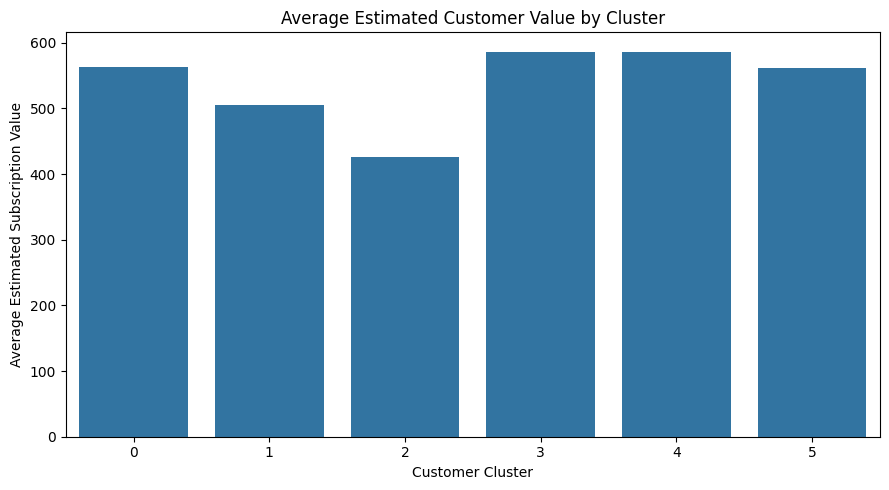

In [9]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=cluster_clv,
    x='cluster',
    y='average_estimated_value'
)

plt.title('Average Estimated Customer Value by Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Average Estimated Subscription Value')
plt.tight_layout()
plt.show()

### Step 10 – Average Estimated Customer Value by Cluster

**Objective:**  
Visualize and compare the average estimated subscription value across six customer clusters.

**Visualization:**  
A bar chart was created to compare average estimated subscription value for each cluster.

**Key Findings:**
- Cluster 4 has the highest average estimated value of 586.46.
- Cluster 3 follows closely with 586.20.
- Cluster 2 has the lowest average estimated value of 425.60.
- Cluster 1 has an average estimated value of 505.65.

**Business Interpretation:**  
Clusters 3 and 4 contain customers with higher average estimated subscription value. These groups may be useful targets for customer retention strategies. Clusters 1 and 2 may need additional engagement and retention efforts.

**Conclusion:**  
Customer cluster analysis helps the business understand how estimated customer value differs across customer groups.

In [10]:
# Calculate churn rate for each customer value category

value_churn = clv_df.groupby('customer_value_category').agg(
    customer_count=('customer_id', 'count'),
    churned_customers=('churned', 'sum'),
    average_estimated_value=('estimated_subscription_value', 'mean')
).reset_index()

value_churn['churn_rate'] = (
    value_churn['churned_customers'] /
    value_churn['customer_count'] * 100
)

value_churn = value_churn.round(2)

display(value_churn)

,customer_value_category,customer_count,churned_customers,average_estimated_value,churn_rate
0,High Value,2002,381,1237.26,19.03
1,Low Value,2000,652,97.18,32.60
2,Medium Value,3998,958,451.06,23.96


### Step 11 – Customer Value and Churn Analysis

**Objective:**  
Understand how customer churn differs across estimated customer value categories.

**Methodology:**  
Grouped customers by value category and calculated customer count, churned customers, average estimated subscription value, and churn rate.

**Key Findings:**
- High Value customers: 2,002 customers, with a churn rate of 19.03%.
- Medium Value customers: 3,998 customers, with a churn rate of 23.96%.
- Low Value customers: 2,000 customers, with a churn rate of 32.60%.
- Low Value customers have the highest churn rate.

**Business Interpretation:**  
Low-value customers may need improved engagement, suitable subscription offers, and better customer support. High-value customers should receive retention attention to protect their contribution to revenue.

**Conclusion:**  
The analysis shows an association between estimated customer value and churn. Lower-value customers have a higher observed churn rate in this dataset.

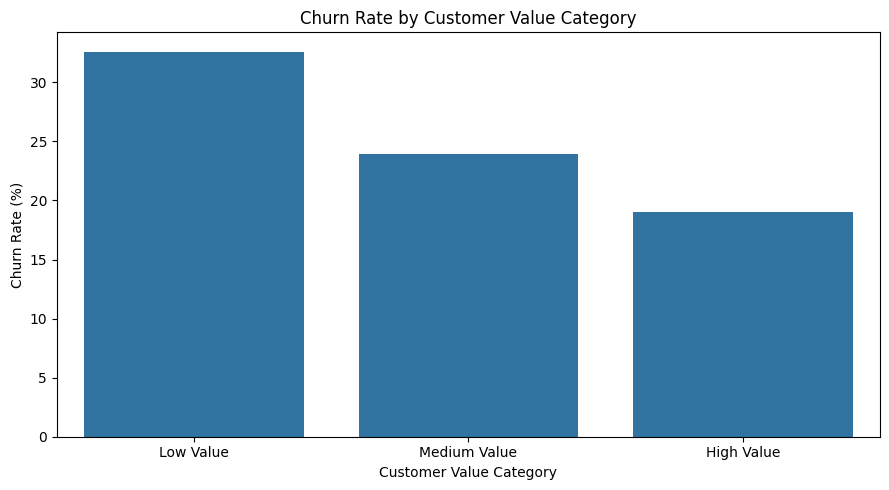

In [11]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=value_churn,
    x='customer_value_category',
    y='churn_rate',
    order=['Low Value', 'Medium Value', 'High Value']
)

plt.title('Churn Rate by Customer Value Category')
plt.xlabel('Customer Value Category')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

### Step 12 – Churn Rate Visualization by Customer Value

**Objective:**  
Visualize the relationship between estimated customer value categories and customer churn.

**Visualization:**  
A bar chart was created to compare churn rates across Low, Medium, and High Value customers.

**Key Findings:**
- Low Value customers have the highest churn rate at 32.60%.
- Medium Value customers have a churn rate of 23.96%.
- High Value customers have the lowest churn rate at 19.03%.

**Business Interpretation:**  
Low Value customers may require improved engagement and retention campaigns. High Value customers should receive attention to maintain their loyalty and reduce the risk of losing valuable subscribers.

**Conclusion:**  
The chart shows that lower estimated customer value is associated with higher observed churn in this dataset.

In [12]:
# Customer distribution by subscription plan and value category

plan_value_table = pd.crosstab(
    clv_df['plan_id'],
    clv_df['customer_value_category']
)

display(plan_value_table)

customer_value_category,High Value,Low Value,Medium Value
plan_id,,,
PLAN01,3,1231,2136
PLAN02,1094,565,1351
PLAN03,905,204,511


### Step 13 – Customer Value Distribution Across Subscription Plans

**Objective:**  
Understand how customer value categories are distributed across different subscription plans.

**Methodology:**  
Created a cross-tabulation between subscription plan and estimated customer value category.

**Key Findings:**
- PLAN01 (Basic) has 1,231 Low Value customers and only 3 High Value customers.
- PLAN02 (Standard) has 1,094 High Value customers.
- PLAN03 (Premium) has 905 High Value customers out of 1,620 customers.
- Premium has a larger proportion of High Value customers compared with Basic.

**Business Interpretation:**  
Premium and Standard plans contain a substantial number of High Value customers. The business can explore suitable upgrades for Basic customers while maintaining the satisfaction of existing Premium subscribers.

**Conclusion:**  
Subscription plans show different customer value distributions, which can help guide customer engagement and upgrade strategies.

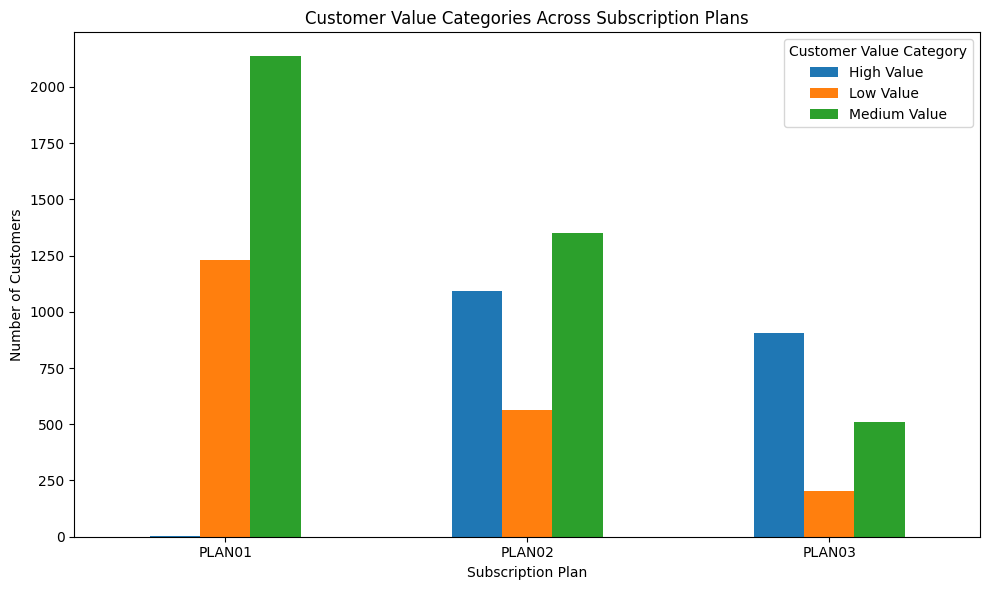

In [13]:
# Visualize customer value categories across subscription plans

plan_value_table.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Customer Value Categories Across Subscription Plans')
plt.xlabel('Subscription Plan')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.legend(title='Customer Value Category')
plt.tight_layout()
plt.show()

### Step 14 – Customer Value Distribution Visualization by Subscription Plan

**Objective:**  
Visualize the distribution of Low, Medium, and High Value customers across subscription plans.

**Visualization:**  
A grouped bar chart was created to compare customer value categories across the three subscription plans.

**Key Findings:**
- Basic (PLAN01) has the largest Medium Value group, with 2,136 customers.
- Standard (PLAN02) has 1,094 High Value customers.
- Premium (PLAN03) has 905 High Value customers out of 1,620.
- Only 3 Basic customers belong to the High Value category.

**Business Interpretation:**  
Premium and Standard plans have a higher concentration of High Value customers. Netflix can explore suitable upgrade opportunities for Basic customers while focusing on retaining Premium and Standard customers.

**Conclusion:**  
Visualizing customer value across subscription plans helps identify opportunities for customer upgrades and retention.

In [14]:
# Overall Customer Lifetime Value Summary

print("TOTAL CUSTOMERS:", len(clv_df))

print(
    "TOTAL ESTIMATED SUBSCRIPTION VALUE:",
    round(clv_df['estimated_subscription_value'].sum(), 2)
)

print(
    "AVERAGE ESTIMATED CUSTOMER VALUE:",
    round(clv_df['estimated_subscription_value'].mean(), 2)
)

print(
    "AVERAGE HISTORICAL PAYMENT REVENUE:",
    round(clv_df['historical_payment_revenue'].mean(), 2)
)

print(
    "HIGH VALUE CUSTOMERS:",
    (clv_df['customer_value_category'] == 'High Value').sum()
)

print(
    "CUSTOMERS WHO CHURNED:",
    clv_df['churned'].sum()
)

print(
    "OVERALL CHURN RATE:",
    round(clv_df['churned'].mean() * 100, 2), "%"
)

TOTAL CUSTOMERS: 8000
TOTAL ESTIMATED SUBSCRIPTION VALUE: 4474701.27
AVERAGE ESTIMATED CUSTOMER VALUE: 559.34
AVERAGE HISTORICAL PAYMENT REVENUE: 188.43
HIGH VALUE CUSTOMERS: 2002
CUSTOMERS WHO CHURNED: 1991
OVERALL CHURN RATE: 24.89 %


# Final Results – Customer Lifetime Value Analysis

## Overall Findings

The analysis was performed on 8,000 Netflix customers.

- Total estimated subscription value: 4,474,701.27
- Average estimated customer value: 559.34
- Average historical payment revenue: 188.43
- High Value customers: 2,002
- Total churned customers: 1,991
- Overall churn rate: 24.89%

## Key Business Insights

1. **Customer Value:** Approximately 25% of customers belong to the High Value category.
2. **Subscription Plans:** Premium customers have the highest average estimated value of 964.44.
3. **Customer Clusters:** Clusters 3 and 4 have the highest average estimated customer value.
4. **Churn Risk:** Low Value customers have the highest churn rate at 32.60%.
5. **Plan Distribution:** Basic customers are concentrated mainly in Low and Medium Value categories.

## Business Recommendations

- Focus on retaining high-value Premium and Standard customers.
- Develop suitable engagement campaigns for Low Value customers.
- Investigate the reasons behind high churn in clusters 1 and 2.
- Explore suitable subscription upgrades for Basic customers.
- Improve customer satisfaction and payment experiences.

## Conclusion

This analysis helped estimate customer value using subscription price and tenure, identify different customer value categories, and compare customer value across subscription plans and clusters.

The findings can help Netflix understand customer behaviour, identify valuable customer groups, and plan better customer retention strategies.

## Limitation

The estimated subscription value is calculated using monthly subscription price and subscription tenure. It is an analytical estimate based on available historical data, not a validated prediction of future customer revenue or profit.

In [15]:
# Save the final customer lifetime value dataset

clv_df.to_csv('/content/netflix_customer_lifetime_value.csv', index=False)

print("CLV dataset saved successfully!")
print("Dataset shape:", clv_df.shape)

# Download the file
from google.colab import files
files.download('/content/netflix_customer_lifetime_value.csv')

CLV dataset saved successfully!
Dataset shape: (8000, 41)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>